# Setup

In [1]:
# Import libraries
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import earthkit.data
import regionmask
import cdsapi

print("All libraries imported successfully!")

c:\Users\Adam\miniforge3\envs\era5-analysis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All libraries imported successfully!


In [9]:
## API key
client = cdsapi.Client(
    quiet=False,
    progress=True,
    retry_max=5,
    sleep_max=120,
)

2026-11-16 17:31:25,548 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


In [10]:

import os
import sys
import importlib
import tempfile
from pathlib import Path

# ============================================================
# 1. CDS API credentials
# ============================================================

# Assumes CDS_URL and CDS_API_KEY have already been defined.
#os.environ["CDSAPI_URL"] = CDS_URL
#os.environ["CDSAPI_KEY"] = CDS_API_KEY

print("=" * 55)
print("ERA5 ENVIRONMENT TEST")
print("=" * 55)

# ============================================================
# 2. Check Python version
# ============================================================

print(f"\nPython version: {sys.version.split()[0]}")
print(f"Python executable: {sys.executable}")

# ============================================================
# 3. Test installed packages
# ============================================================

packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "xarray": "xarray",
    "netCDF4": "netCDF4",
    "cfgrib": "cfgrib",
    "eccodes": "eccodes",
    "dask": "dask",
    "scipy": "scipy",
    "matplotlib": "matplotlib",
    "cartopy": "cartopy",
    "sklearn": "scikit-learn",
    "cdsapi": "cdsapi",
    "earthkit.data": "earthkit-data",
    "regionmask": "regionmask",
    "xeofs": "xeofs",
}

failed = []

print("\nChecking installed packages:\n")

for module, package in packages.items():
    try:
        importlib.import_module(module)
        print(f"  [OK] {package}")
    except Exception as e:
        print(f"  [FAIL] {package}: {e}")
        failed.append(package)

# ============================================================
# 4. Check CDS API configuration
# ============================================================

print("\nChecking CDS API configuration:\n")

url = os.environ.get("CDSAPI_URL")
key = os.environ.get("CDSAPI_KEY")

if url and key:
    print(f"  [OK] CDS API URL: {url}")
    print("  [OK] CDS API key is configured (hidden)")
else:
    print("  [FAIL] CDS API credentials missing")

# ============================================================
# 5. Test Xarray and NumPy
# ============================================================

print("\nTesting Xarray and NumPy:\n")

try:
    import numpy as np
    import xarray as xr

    data = xr.DataArray(
        np.random.default_rng(42).random((10, 20)),
        dims=["latitude", "longitude"],
        coords={
            "latitude": np.linspace(50, 60, 10),
            "longitude": np.linspace(-10, 10, 20),
        },
        name="temperature",
    )

    print(f"  [OK] Created DataArray: {data.shape}")
    print(f"  [OK] Mean value: {data.mean().item():.4f}")

except Exception as e:
    print(f"  [FAIL] Xarray test: {e}")
    failed.append("xarray computation")

# ============================================================
# 6. Test NetCDF writing and reading
# ============================================================

print("\nTesting NetCDF:\n")

try:
    with tempfile.TemporaryDirectory() as tmp:
        path = Path(tmp) / "test.nc"

        data.to_netcdf(path, engine="netcdf4")

        with xr.open_dataarray(path, engine="netcdf4") as loaded:
            np.testing.assert_allclose(
                loaded.values, data.values
            )

    print("  [OK] NetCDF write/read successful")

except Exception as e:
    print(f"  [FAIL] NetCDF test: {e}")
    failed.append("NetCDF read/write")

# ============================================================
# 7. Test CDS API client initialization
# ============================================================

print("\nTesting CDS API client:\n")

try:
    import cdsapi

    client = client

    print("  [OK] CDS API client initialized")
    print("  [INFO] No download attempted yet")

except Exception as e:
    print(f"  [FAIL] CDS API client: {e}")
    failed.append("CDS API client")

# ============================================================
# 8. Summary
# ============================================================

print("\n" + "=" * 55)

if not failed:
    print("SUCCESS: All local environment tests passed!")
else:
    print(f"WARNING: {len(failed)} test(s) failed")
    print("Failed:", ", ".join(failed))

print("=" * 55)


ERA5 ENVIRONMENT TEST

Python version: 3.12.16
Python executable: c:\Users\Adam\miniforge3\envs\era5-analysis\python.exe

Checking installed packages:

  [OK] numpy
  [OK] pandas
  [OK] xarray
  [OK] netCDF4
  [OK] cfgrib
  [OK] eccodes
  [OK] dask
  [OK] scipy
  [OK] matplotlib
  [OK] cartopy
  [OK] scikit-learn
  [OK] cdsapi
  [OK] earthkit-data
  [OK] regionmask
  [OK] xeofs

Checking CDS API configuration:

  [FAIL] CDS API credentials missing

Testing Xarray and NumPy:

  [OK] Created DataArray: (10, 20)
  [OK] Mean value: 0.4939

Testing NetCDF:

  [OK] NetCDF write/read successful

Testing CDS API client:

  [OK] CDS API client initialized
  [INFO] No download attempted yet

SUCCESS: All local environment tests passed!


ERA5 END-TO-END ENVIRONMENT TEST

[2/6] Downloading ERA5 data...
[OK] Existing ERA5 file found
File: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5_uk_temperature.nc
Size: 28.50 KB

[3/6] Opening ERA5 NetCDF dataset...

Dataset:
<xarray.Dataset> Size: 10kB
Dimensions:     (valid_time: 1, latitude: 41, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2024-01-01T12:00:00
  * latitude    (latitude) float64 328B 59.0 58.75 58.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
    expver      <U4 16B ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 9kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:       

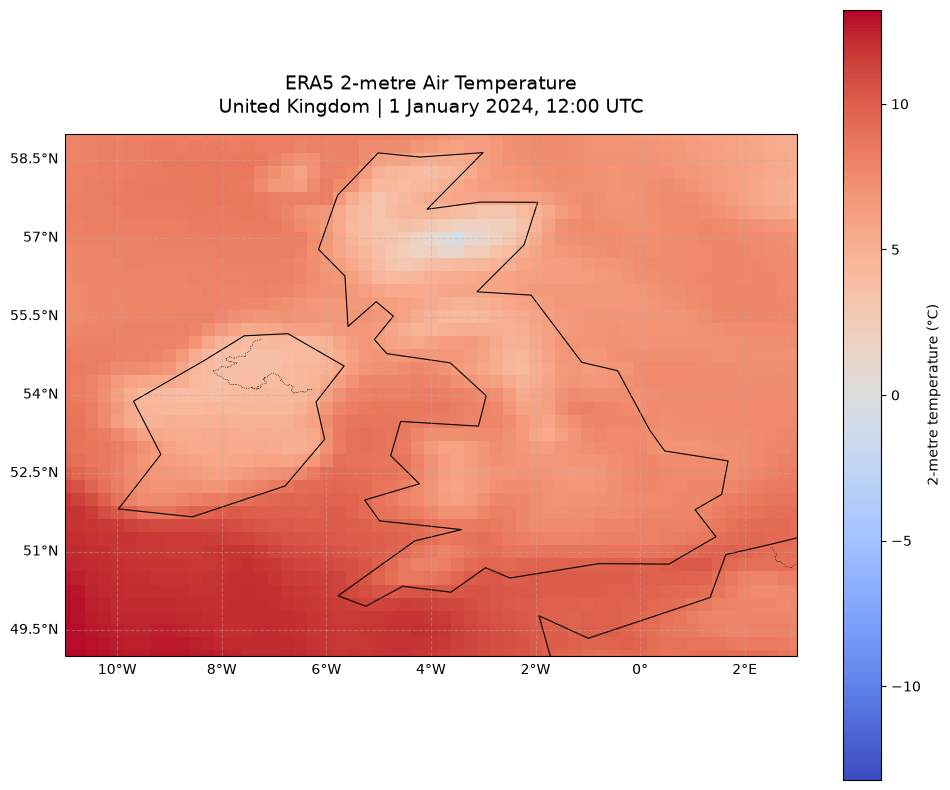

[OK] Map saved: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5_uk_temperature.png

[6/6] Running final checks...

ERA5 END-TO-END TEST RESULTS
[FAIL] CDS API credentials configured
[PASS] ERA5 NetCDF file exists
[PASS] ERA5 NetCDF file is non-empty
[PASS] Temperature variable available
[PASS] Temperature converted to Celsius
[PASS] Temperature values are finite
[PASS] Temperature statistics calculated
[PASS] Temperature map saved


In [ ]:
import os
from pathlib import Path

import cdsapi
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ============================================================
# ERA5 END-TO-END ENVIRONMENT TEST
# ============================================================

print("=" * 60)
print("ERA5 END-TO-END ENVIRONMENT TEST")
print("=" * 60)

# ============================================================
# 1. CDS API CREDENTIALS
# ============================================================

# Assumes CDS_URL and CDS_API_KEY are already defined.
# Do not print or commit your API key.

#os.environ["CDSAPI_URL"] = CDS_URL
#os.environ["CDSAPI_KEY"] = CDS_API_KEY

#print("\n[1/6] Checking CDS API credentials...")

#assert os.environ.get("CDSAPI_URL"), "Missing CDS API URL"
#assert os.environ.get("CDSAPI_KEY"), "Missing CDS API key"

#print("[OK] CDS API credentials configured")

# ============================================================
# 2. DOWNLOAD ERA5 DATA
# ============================================================

print("\n[2/6] Downloading ERA5 data...")

data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

output_file = data_dir / "uk" / "era5_uk_temperature.nc"

if not output_file.exists():

    client.retrieve(
        "reanalysis-era5-single-levels",
        {
            "product_type": ["reanalysis"],
            "variable": ["2m_temperature"],
            "year": ["2024"],
            "month": ["01"],
            "day": ["01"],
            "time": ["12:00"],
            "data_format": "netcdf",
            "download_format": "unarchived",
            "area": [59, -11, 49, 3],
        },
        str(output_file.resolve()),
    )

    print("[OK] ERA5 download complete")

else:
    print("[OK] Existing ERA5 file found")

print(f"File: {output_file.resolve()}")
print(f"Size: {output_file.stat().st_size / 1024:.2f} KB")

# ============================================================
# 3. OPEN AND INSPECT DATASET
# ============================================================

print("\n[3/6] Opening ERA5 NetCDF dataset...")

ds = xr.open_dataset(output_file)

print("\nDataset:")
print(ds)

print("\nVariables:", list(ds.data_vars))
print("Dimensions:", dict(ds.sizes))
print("Coordinates:", list(ds.coords))

assert "t2m" in ds.data_vars, "Temperature variable t2m missing"

print("\n[OK] NetCDF dataset opened successfully")

# ============================================================
# 4. TEMPERATURE ANALYSIS
# ============================================================

print("\n[4/6] Analysing ERA5 temperature...")

# Convert Kelvin to Celsius
temperature_c = (ds["t2m"] - 273.15).squeeze()

temperature_c.attrs["units"] = "degC"
temperature_c.attrs["long_name"] = "2-metre air temperature"

# Calculate statistics
t_min = temperature_c.min().item()
t_max = temperature_c.max().item()
t_mean = temperature_c.mean().item()
t_std = temperature_c.std().item()

print("\nTemperature statistics:")
print("-" * 40)
print(f"Minimum:            {t_min:.2f} °C")
print(f"Maximum:            {t_max:.2f} °C")
print(f"Mean:               {t_mean:.2f} °C")
print(f"Standard deviation: {t_std:.2f} °C")

assert np.isfinite(temperature_c.values).all(), (
    "Temperature contains NaN or infinite values"
)

print("\n[OK] Temperature calculations successful")

# ============================================================
# 5. VISUALISE TEMPERATURE WITH CARTOPY
# ============================================================

print("\n[5/6] Generating ERA5 temperature map...")

fig_dir = Path("figures")
fig_dir.mkdir(parents=True, exist_ok=True)

fig = plt.figure(figsize=(10, 8))

ax = plt.axes(
    projection=ccrs.PlateCarree()
)

# Plot temperature field
temperature_c.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
    cbar_kwargs={
        "label": "2-metre temperature (°C)"
    }
)

# Geographic features
ax.coastlines(
    resolution="110m",
    linewidth=0.8
)

ax.add_feature(
    cfeature.BORDERS,
    linestyle=":",
    linewidth=0.5
)

# Map extent
ax.set_extent(
    [-11, 3, 49, 59],
    crs=ccrs.PlateCarree()
)

# Gridlines
ax.gridlines(
    draw_labels={"bottom": "x", "left": "y"},
    linestyle="--",
    alpha=0.4
)

# Title
ax.set_title(
    "ERA5 2-metre Air Temperature\n"
    "United Kingdom | 1 January 2024, 12:00 UTC",
    fontsize=14,
    pad=15
)

plt.tight_layout()

# Save figure
figure_file = fig_dir / "era5_uk_temperature.png"

plt.savefig(
    figure_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"[OK] Map saved: {figure_file.resolve()}")

# ============================================================
# 6. FINAL VERIFICATION
# ============================================================

print("\n[6/6] Running final checks...")

checks = {
    "CDS API credentials configured":
        bool(os.environ.get("CDSAPI_URL")) and
        bool(os.environ.get("CDSAPI_KEY")),

    "ERA5 NetCDF file exists":
        output_file.exists(),

    "ERA5 NetCDF file is non-empty":
        output_file.stat().st_size > 0,

    "Temperature variable available":
        "t2m" in ds.data_vars,

    "Temperature converted to Celsius":
        temperature_c.attrs.get("units") == "degC",

    "Temperature values are finite":
        bool(np.isfinite(temperature_c.values).all()),

    "Temperature statistics calculated":
        bool(np.isfinite([t_min, t_max, t_mean, t_std]).all()),

    "Temperature map saved":
        figure_file.exists(),
}

print("\n" + "=" * 60)
print("ERA5 END-TO-END TEST RESULTS")
print("=" * 60)

for name, passed in checks.items():
    status = "[PASS]" if passed else "[FAIL]"
    print(f"{status} {name}")

print("=" * 60)

if all(checks.values()):
    print("SUCCESS: ERA5 END-TO-END WORKFLOW IS OPERATIONAL!")
else:
    print("WARNING: Some tests failed.")

print("=" * 60)

# Close dataset
ds.close()

In [5]:

import os
from pathlib import Path

import cdsapi
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# ============================================================
# ERA5 EL NINO ANALYSIS: 2006-2025
# Monthly Pacific Sea Surface Temperature
# ============================================================

START_YEAR = 2006
END_YEAR = 2025

DATA_DIR = Path("data/era5_pacific")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Credentials should already be defined securely
os.environ["CDSAPI_URL"] = CDS_URL
os.environ["CDSAPI_KEY"] = CDS_API_KEY

client = cdsapi.Client()

# ============================================================
# 1. DOWNLOAD MONTHLY ERA5 SST
# ============================================================

print("Downloading ERA5 monthly Pacific SST...")

files = []

for year in range(START_YEAR, END_YEAR + 1):

    filename = DATA_DIR / f"era5_sst_{year}.nc"

    if not filename.exists():

        print(f"Downloading {year}...")

        client.retrieve(
            "reanalysis-era5-single-levels-monthly-means",
            {
                "product_type": "monthly_averaged_reanalysis",
                "variable": "sea_surface_temperature",
                "year": str(year),
                "month": [
                    f"{m:02d}" for m in range(1, 13)
                ],
                "time": "00:00",
                "data_format": "netcdf",
                "download_format": "unarchived",

                # Pacific: 20S-20N, 120E-80W
                # CDS longitudes use -180 to 180.
                # Request across the dateline using
                # 80W to 120E, then select the Pacific.
                "area": [20, -80, -20, 120],
            },
            str(filename.resolve()),
        )

    files.append(filename)

print("Downloads complete.")

# ============================================================
# 2. LOAD AND COMBINE DATA
# ============================================================

datasets = [xr.open_dataset(f) for f in files]

ds = xr.combine_by_coords(datasets)

# Handle ERA5 time coordinate naming
if "valid_time" in ds.coords:
    ds = ds.rename({"valid_time": "time"})

# Remove singleton dimensions
sst = ds["sst"].squeeze(drop=True)

# Convert longitude to 0-360 degrees
sst = sst.assign_coords(
    longitude=sst.longitude % 360
).sortby("longitude")

# Select Pacific: 120E to 280E
sst = sst.sel(
    latitude=slice(20, -20),
    longitude=slice(120, 280)
)

# Convert Kelvin to Celsius
sst = sst - 273.15
sst.attrs["units"] = "degC"

print("\nDataset:")
print(sst)

# ============================================================
# 3. CALCULATE MONTHLY CLIMATOLOGY AND ANOMALIES
# ============================================================

# 20-year monthly climatology
climatology = sst.groupby("time.month").mean("time")

# Remove seasonal cycle
anomalies = (
    sst.groupby("time.month") - climatology
)

# Mean SST over all 20 years
mean_sst = sst.mean("time")

# ============================================================
# 4. PLOT 20-YEAR MEAN PACIFIC SST
# ============================================================

fig = plt.figure(figsize=(13, 6))

ax = plt.axes(
    projection=ccrs.PlateCarree(
        central_longitude=180
    )
)

mean_sst.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="turbo",
    vmin=20,
    vmax=31,
    cbar_kwargs={
        "label": "Sea Surface Temperature (°C)"
    }
)

ax.coastlines()
ax.set_extent(
    [120, 280, -20, 20],
    crs=ccrs.PlateCarree()
)

ax.set_title(
    "Mean Pacific Sea Surface Temperature\n"
    "ERA5 | 2006-2025"
)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "pacific_mean_sst.png",
    dpi=200
)
plt.show()

# ============================================================
# 5. NINO 3.4 REGION SST ANOMALIES
# ============================================================

# Nino 3.4:
# Latitude: 5S to 5N
# Longitude: 170W to 120W (190E to 240E)

nino34 = anomalies.sel(
    latitude=slice(5, -5),
    longitude=slice(190, 240)
)

# Area-weighted mean using cosine(latitude)
weights = np.cos(
    np.deg2rad(nino34.latitude)
)

nino34_index = nino34.weighted(weights).mean(
    dim=["latitude", "longitude"]
)

# 3-month running mean for visualisation
nino34_smooth = nino34_index.rolling(
    time=3,
    center=True
).mean()

# ============================================================
# 6. PLOT NINO 3.4 TIME SERIES
# ============================================================

fig, ax = plt.subplots(figsize=(14, 5))

dates = pd.to_datetime(
    nino34_smooth.time.values
)

values = nino34_smooth.values

ax.plot(
    dates,
    values,
    color="black",
    linewidth=1.2
)

ax.fill_between(
    dates, values, 0,
    where=values > 0,
    color="red",
    alpha=0.5
)

ax.fill_between(
    dates, values, 0,
    where=values < 0,
    color="blue",
    alpha=0.5
)

ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(0.5, color="red", linestyle="--")
ax.axhline(-0.5, color="blue", linestyle="--")

ax.set_title(
    "Niño 3.4 Sea Surface Temperature Anomalies\n"
    "ERA5 | 2006-2025 | 3-Month Running Mean"
)

ax.set_ylabel("SST anomaly (°C)")
ax.set_xlabel("Year")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "nino34_anomalies.png",
    dpi=200
)
plt.show()

# ============================================================
# 7. HOVMOLLER DIAGRAM
# Equatorial Pacific SST anomalies through time
# ============================================================

equatorial = anomalies.sel(
    latitude=slice(5, -5)
)

weights_eq = np.cos(
    np.deg2rad(equatorial.latitude)
)

hovmoller = equatorial.weighted(
    weights_eq
).mean("latitude")

fig, ax = plt.subplots(figsize=(13, 8))

hovmoller.plot(
    ax=ax,
    x="longitude",
    y="time",
    cmap="RdBu_r",
    vmin=-3,
    vmax=3,
    cbar_kwargs={
        "label": "SST anomaly (°C)"
    }
)

ax.set_title(
    "Equatorial Pacific SST Anomalies\n"
    "ERA5 | 2006-2025"
)

ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Time")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "pacific_hovmoller.png",
    dpi=200
)
plt.show()

# ============================================================
# 8. SAVE NINO 3.4 INDEX
# ============================================================

nino34_index.to_dataframe(
    name="sst_anomaly_C"
).to_csv(
    DATA_DIR / "nino34_monthly_anomalies.csv"
)

print("\n" + "=" * 55)
print("ANALYSIS COMPLETE")
print("=" * 55)
print("Months analysed:", sst.sizes["time"])
print("Mean Pacific SST:", round(float(mean_sst.mean()), 2))
print("Figures saved to:", FIG_DIR.resolve())
print("=" * 55)


2026-11-16 15:37:00,425 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


2026-11-16 15:37:00,747 INFO Request ID is 20dc0d31-7acf-4cb4-95d7-bc974743fa20
2026-11-16 15:37:00,815 INFO status has been updated to accepted
Recovering from connection error [('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))], attempt 1 of 500
Retrying in 120 seconds


KeyboardInterrupt: 

In [ ]:

import os
import time
from pathlib import Path

import cdsapi
import xarray as xr
import matplotlib.pyplot as plt

# CDS_URL and CDS_API_KEY already defined
os.environ["CDSAPI_URL"] = CDS_URL
os.environ["CDSAPI_KEY"] = CDS_API_KEY

output = Path("era5_sst_test_2006_01.nc")

client = cdsapi.Client(
    url=CDS_URL,
    key=CDS_API_KEY
)

request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "variable": ["sea_surface_temperature"],
    "year": ["2006"],
    "month": ["01"],
    "time": ["00:00"],
    "data_format": "netcdf",
    "download_format": "unarchived",

    # Central/eastern tropical Pacific
    # North, West, South, East
    "area": [20, -180, -20, -80],

    # Coarser grid
    "grid": [1.0, 1.0],
}

print("Submitting ERA5 test request...")
start = time.time()

client.retrieve(
    "reanalysis-era5-single-levels-monthly-means",
    request,
    str(output.resolve())
)

print(f"Download completed in {(time.time()-start)/60:.1f} minutes")

with xr.open_dataset(output) as ds:
    print(ds)

    sst = (ds["sst"] - 273.15).squeeze().load()

sst.plot(
    figsize=(12, 5),
    cmap="turbo",
    vmin=20,
    vmax=31,
    cbar_kwargs={"label": "SST (°C)"}
)

plt.title("ERA5 Pacific SST — January 2006")
plt.tight_layout()
plt.show()


2026-11-16 16:14:13,488 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


Submitting ERA5 test request...


2026-11-16 16:14:16,095 INFO Request ID is f413f468-4a4e-41dc-ba04-c00d3961c9f6
2026-11-16 16:14:16,297 INFO status has been updated to accepted


NOAA ERSSTv5 - EL NINO ANALYSIS

[1/8] Using existing NOAA dataset
File: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\noaa\sst.mnmean.nc
Size: 154.85 MB

[2/8] Loading tropical Pacific SST...

Original dataset dimensions:
{'time': 2074, 'nbnds': 2, 'lat': 89, 'lon': 180}

Original latitude range:
88.0 to -88.0

Original longitude range:
0.0 to 358.0

Selected SST dimensions:
{'time': 240, 'lat': 21, 'lon': 81}

[OK] Pacific SST selected successfully
Minimum SST: 15.83 °C
Maximum SST: 31.96 °C

[3/8] Calculating SST climatology and anomalies...
[OK] Monthly climatology calculated
[OK] Monthly anomalies calculated
[OK] 20-year mean SST calculated

[4/8] Plotting mean Pacific SST...


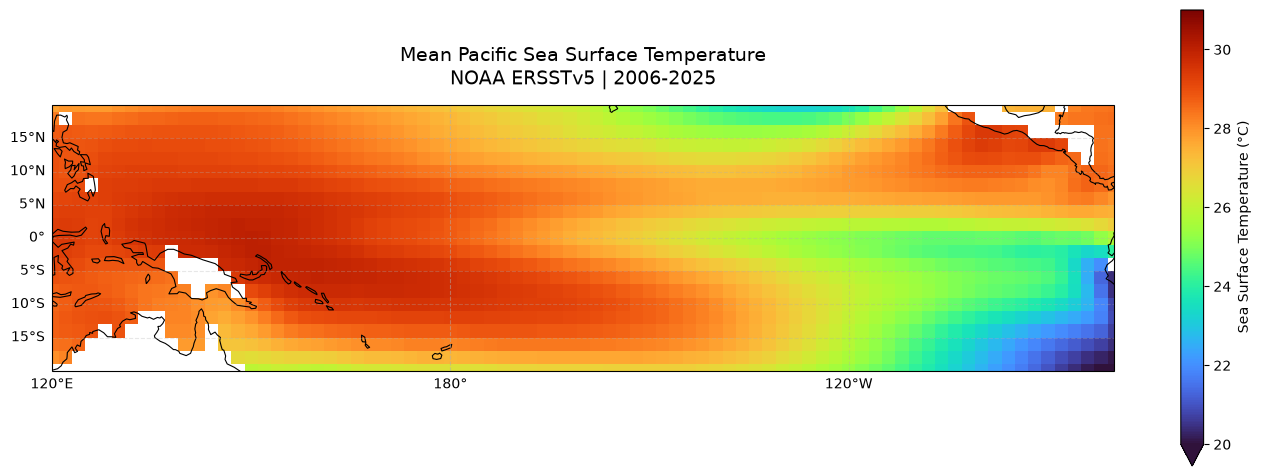

[OK] Mean SST map saved

[5/8] Calculating Niño 3.4 index...
[OK] Niño 3.4 index calculated
Maximum anomaly: 2.78 °C
Minimum anomaly: -1.58 °C

[6/8] Plotting Niño 3.4 anomalies...


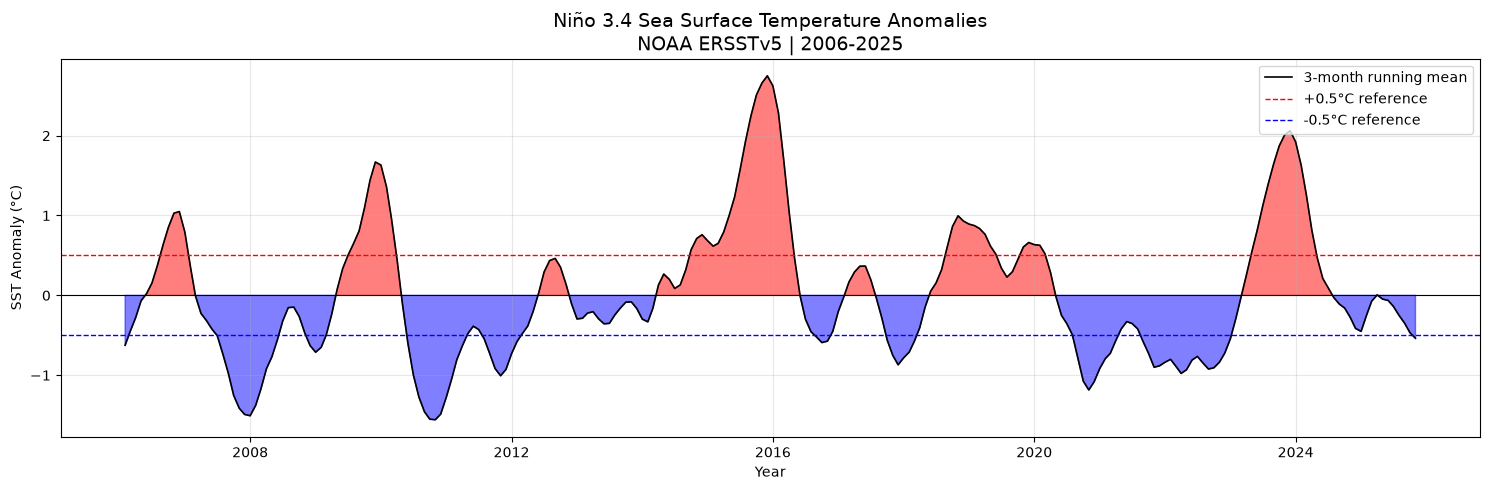

[OK] Niño 3.4 time series saved

[7/8] Plotting Pacific Hovmöller diagram...


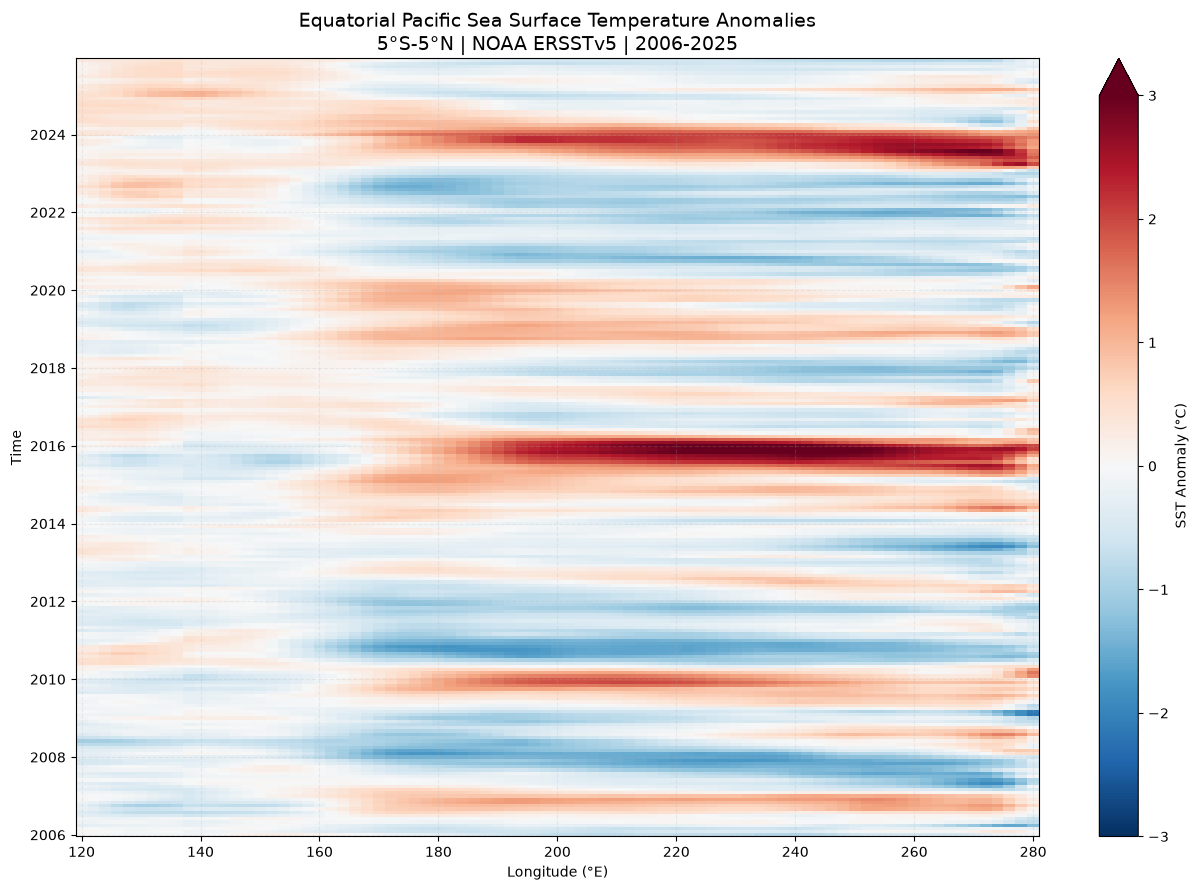

[OK] Hovmöller diagram saved

[8/8] Saving Niño 3.4 index...

NOAA ERSSTv5 ANALYSIS RESULTS
[PASS] NOAA dataset downloaded
[PASS] 240 months selected
[PASS] Latitude selection valid
[PASS] Longitude selection valid
[PASS] Mean SST calculated
[PASS] Niño 3.4 index calculated
[PASS] Mean SST map saved
[PASS] Niño 3.4 plot saved
[PASS] Hovmöller diagram saved
[PASS] CSV saved
[PASS] NetCDF anomalies saved
SUCCESS: ALL TESTS PASSED!

Months analysed: 240
Latitude points: 21
Longitude points: 81

Output directory:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures

Data directory:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\noaa


In [7]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path
import urllib.request

# ============================================================
# NOAA ERSSTv5 - EL NINO ANALYSIS
# Monthly Pacific Sea Surface Temperature: 2006-2025
# ============================================================

START_YEAR = 2006
END_YEAR = 2025

DATA_DIR = Path("data/noaa")
FIG_DIR = Path("figures")

DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

url = (
    "https://downloads.psl.noaa.gov/Datasets/"
    "noaa.ersst.v5/sst.mnmean.nc"
)

file_path = DATA_DIR / "sst.mnmean.nc"

# ============================================================
# 1. DOWNLOAD NOAA DATA
# ============================================================

print("=" * 60)
print("NOAA ERSSTv5 - EL NINO ANALYSIS")
print("=" * 60)

if not file_path.exists():

    print("\n[1/8] Downloading NOAA ERSSTv5...")

    # Download to a temporary file to avoid retaining
    # incomplete downloads if interrupted.
    temp_path = file_path.with_suffix(".nc.part")

    try:
        urllib.request.urlretrieve(url, temp_path)
        temp_path.replace(file_path)
    except Exception:
        temp_path.unlink(missing_ok=True)
        raise

    print("[OK] Download complete")

else:
    print("\n[1/8] Using existing NOAA dataset")

print(f"File: {file_path.resolve()}")
print(f"Size: {file_path.stat().st_size / 1024**2:.2f} MB")

# ============================================================
# 2. LOAD AND SELECT TROPICAL PACIFIC
# ============================================================

print("\n[2/8] Loading tropical Pacific SST...")

ds = xr.open_dataset(file_path)

print("\nOriginal dataset dimensions:")
print(dict(ds.sizes))

print("\nOriginal latitude range:")
print(ds.lat.values[0], "to", ds.lat.values[-1])

print("\nOriginal longitude range:")
print(ds.lon.values[0], "to", ds.lon.values[-1])

# IMPORTANT:
# Sort coordinates into ascending order.
# This fixes the empty latitude selection problem.

sst = ds["sst"].sortby("lat").sortby("lon")

# Select the tropical Pacific:
# Latitude: 20S to 20N
# Longitude: 120E to 80W (280E)
# Time: January 2006 to December 2025

sst = sst.sel(
    time=slice(
        f"{START_YEAR}-01-01",
        f"{END_YEAR}-12-31"
    ),
    lat=slice(-20, 20),
    lon=slice(120, 280)
)

# Load selected data into memory
sst = sst.load()

print("\nSelected SST dimensions:")
print(dict(sst.sizes))

# Verify data selection
assert sst.sizes["time"] == 240, (
    f"Expected 240 months, got {sst.sizes['time']}"
)

assert sst.sizes["lat"] > 0, (
    "Latitude selection is empty"
)

assert sst.sizes["lon"] > 0, (
    "Longitude selection is empty"
)

assert bool(sst.notnull().any()), (
    "Selected SST contains no valid data"
)

print("\n[OK] Pacific SST selected successfully")

print(f"Minimum SST: {float(sst.min()):.2f} °C")
print(f"Maximum SST: {float(sst.max()):.2f} °C")

# ============================================================
# 3. CALCULATE CLIMATOLOGY AND ANOMALIES
# ============================================================

print("\n[3/8] Calculating SST climatology and anomalies...")

# Monthly climatology:
# Mean January, mean February, etc.
climatology = sst.groupby("time.month").mean(
    dim="time"
)

# Monthly anomalies relative to 2006-2025 climatology
anomalies = (
    sst.groupby("time.month") - climatology
)

# Mean SST over the entire 20-year period
mean_sst = sst.mean(dim="time")

print("[OK] Monthly climatology calculated")
print("[OK] Monthly anomalies calculated")
print("[OK] 20-year mean SST calculated")

# ============================================================
# 4. PLOT 20-YEAR MEAN PACIFIC SST
# ============================================================

print("\n[4/8] Plotting mean Pacific SST...")

fig = plt.figure(figsize=(14, 6))

ax = plt.axes(
    projection=ccrs.PlateCarree(
        central_longitude=180
    )
)

mean_sst.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="turbo",
    vmin=20,
    vmax=31,
    cbar_kwargs={
        "label": "Sea Surface Temperature (°C)",
        "shrink": 0.8
    }
)

ax.coastlines(
    resolution="110m",
    linewidth=0.8
)

ax.set_extent(
    [120, 280, -20, 20],
    crs=ccrs.PlateCarree()
)

ax.gridlines(
    draw_labels={"bottom": "x", "left": "y"},
    linestyle="--",
    alpha=0.3
)

ax.set_title(
    "Mean Pacific Sea Surface Temperature\n"
    "NOAA ERSSTv5 | 2006-2025",
    fontsize=14,
    pad=15
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "pacific_mean_sst.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("[OK] Mean SST map saved")

# ============================================================
# 5. CALCULATE NINO 3.4 SST ANOMALY INDEX
# ============================================================

print("\n[5/8] Calculating Niño 3.4 index...")

# Niño 3.4 region:
# Latitude: 5S to 5N
# Longitude: 170W to 120W
# Converted to 0-360 longitude: 190E to 240E

nino34 = anomalies.sel(
    lat=slice(-5, 5),
    lon=slice(190, 240)
)

assert nino34.sizes["lat"] > 0
assert nino34.sizes["lon"] > 0

# Area weighting using cosine of latitude
weights = np.cos(
    np.deg2rad(nino34.lat)
)

nino34_index = nino34.weighted(
    weights
).mean(
    dim=["lat", "lon"]
)

# Three-month running mean
nino34_smooth = nino34_index.rolling(
    time=3,
    center=True
).mean()

print("[OK] Niño 3.4 index calculated")

print(
    f"Maximum anomaly: "
    f"{float(nino34_index.max()):.2f} °C"
)

print(
    f"Minimum anomaly: "
    f"{float(nino34_index.min()):.2f} °C"
)

# ============================================================
# 6. PLOT NINO 3.4 TIME SERIES
# ============================================================

print("\n[6/8] Plotting Niño 3.4 anomalies...")

fig, ax = plt.subplots(figsize=(15, 5))

dates = pd.to_datetime(
    nino34_smooth.time.values
)

values = nino34_smooth.values

# Main time series
ax.plot(
    dates,
    values,
    color="black",
    linewidth=1.2,
    label="3-month running mean"
)

# Warm anomalies
ax.fill_between(
    dates,
    values,
    0,
    where=values > 0,
    color="red",
    alpha=0.5,
    interpolate=True
)

# Cold anomalies
ax.fill_between(
    dates,
    values,
    0,
    where=values < 0,
    color="blue",
    alpha=0.5,
    interpolate=True
)

# Reference lines
ax.axhline(
    0,
    color="black",
    linewidth=0.8
)

ax.axhline(
    0.5,
    color="red",
    linestyle="--",
    linewidth=1,
    label="+0.5°C reference"
)

ax.axhline(
    -0.5,
    color="blue",
    linestyle="--",
    linewidth=1,
    label="-0.5°C reference"
)

ax.set_title(
    "Niño 3.4 Sea Surface Temperature Anomalies\n"
    "NOAA ERSSTv5 | 2006-2025",
    fontsize=14
)

ax.set_ylabel("SST Anomaly (°C)")
ax.set_xlabel("Year")

ax.grid(alpha=0.3)
ax.legend(loc="upper right")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "nino34_anomalies.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("[OK] Niño 3.4 time series saved")

# ============================================================
# 7. EQUATORIAL PACIFIC HOVMOLLER DIAGRAM
# ============================================================

print("\n[7/8] Plotting Pacific Hovmöller diagram...")

# Select equatorial Pacific (5S to 5N)
equatorial = anomalies.sel(
    lat=slice(-5, 5)
)

# Latitude weighting
weights_eq = np.cos(
    np.deg2rad(equatorial.lat)
)

# Average over equatorial latitude band
hovmoller = equatorial.weighted(
    weights_eq
).mean("lat")

fig, ax = plt.subplots(figsize=(13, 9))

hovmoller.plot(
    ax=ax,
    x="lon",
    y="time",
    cmap="RdBu_r",
    vmin=-3,
    vmax=3,
    cbar_kwargs={
        "label": "SST Anomaly (°C)"
    }
)

ax.set_title(
    "Equatorial Pacific Sea Surface Temperature Anomalies\n"
    "5°S-5°N | NOAA ERSSTv5 | 2006-2025",
    fontsize=14
)

ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Time")

ax.grid(
    linestyle="--",
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "pacific_hovmoller.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("[OK] Hovmöller diagram saved")

# ============================================================
# 8. SAVE DATA AND FINAL VERIFICATION
# ============================================================

print("\n[8/8] Saving Niño 3.4 index...")

csv_file = (
    DATA_DIR / "nino34_monthly_anomalies.csv"
)

nino34_index.to_dataframe(
    name="sst_anomaly_C"
).to_csv(csv_file)

# Save calculated anomalies to NetCDF
anomaly_file = DATA_DIR / "pacific_sst_anomalies.nc"

anomalies.to_dataset(
    name="sst_anomaly"
).to_netcdf(anomaly_file)

# Final checks
checks = {
    "NOAA dataset downloaded":
        file_path.exists(),

    "240 months selected":
        sst.sizes["time"] == 240,

    "Latitude selection valid":
        sst.sizes["lat"] > 0,

    "Longitude selection valid":
        sst.sizes["lon"] > 0,

    "Mean SST calculated":
        bool(mean_sst.notnull().any()),

    "Niño 3.4 index calculated":
        bool(nino34_index.notnull().any()),

    "Mean SST map saved":
        (FIG_DIR / "pacific_mean_sst.png").exists(),

    "Niño 3.4 plot saved":
        (FIG_DIR / "nino34_anomalies.png").exists(),

    "Hovmöller diagram saved":
        (FIG_DIR / "pacific_hovmoller.png").exists(),

    "CSV saved":
        csv_file.exists(),

    "NetCDF anomalies saved":
        anomaly_file.exists(),
}

print("\n" + "=" * 60)
print("NOAA ERSSTv5 ANALYSIS RESULTS")
print("=" * 60)

for name, passed in checks.items():
    status = "[PASS]" if passed else "[FAIL]"
    print(f"{status} {name}")

print("=" * 60)

if all(checks.values()):
    print("SUCCESS: ALL TESTS PASSED!")
else:
    print("WARNING: Some tests failed.")

print(f"\nMonths analysed: {sst.sizes['time']}")
print(f"Latitude points: {sst.sizes['lat']}")
print(f"Longitude points: {sst.sizes['lon']}")

print("\nOutput directory:")
print(FIG_DIR.resolve())

print("\nData directory:")
print(DATA_DIR.resolve())

print("=" * 60)

# Close original dataset
ds.close()


ERA5 MEAN SEA-LEVEL PRESSURE VALIDATION

[1/7] Checking file integrity...
File: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5\era5_global\era5_mean_sea_level_pressure_1940_2025.nc
File size: 1.23 GB

Dataset:
<xarray.Dataset> Size: 4GB
Dimensions:     (valid_time: 1032, latitude: 721, longitude: 1440)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8kB 1940-01-01 ... 2025-12-01
    expver      (valid_time) <U4 17kB dask.array<chunksize=(1032,), meta=np.ndarray>
  * latitude    (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude   (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    number      int64 8B ...
Data variables:
    msl         (valid_time, latitude, longitude) float32 4GB dask.array<chunksize=(148, 103, 206), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:            

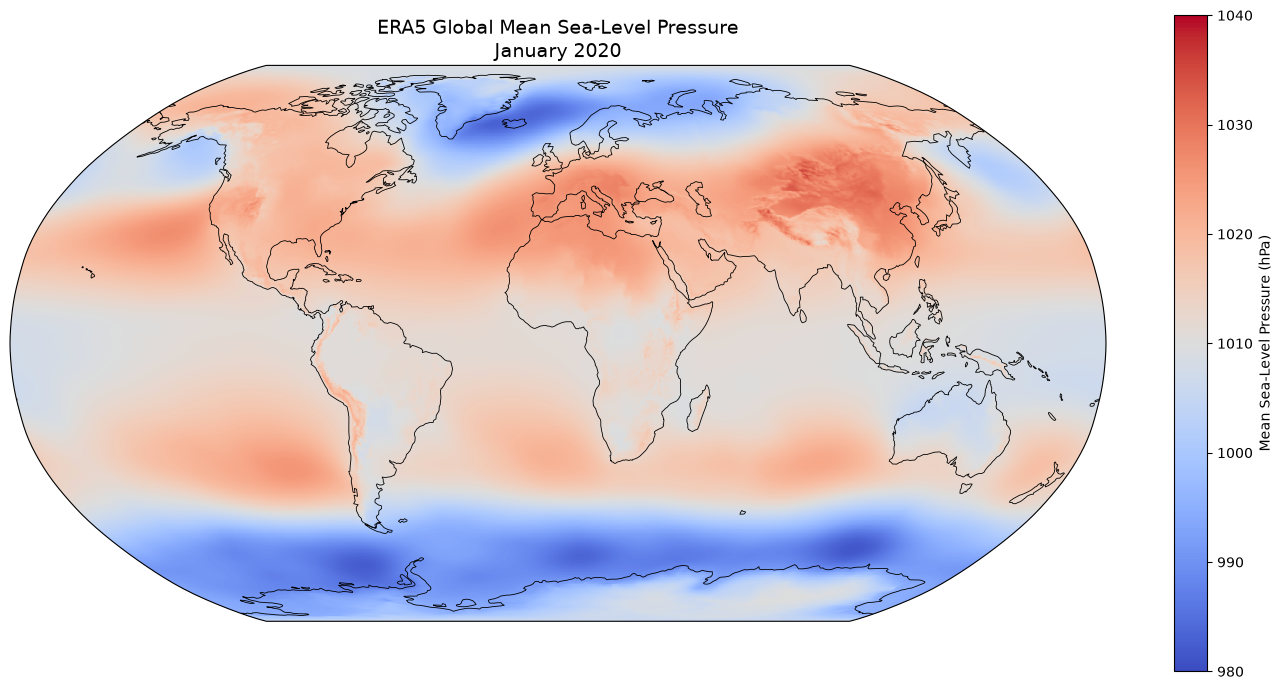


[7/7] Plotting tropical Pacific pressure...


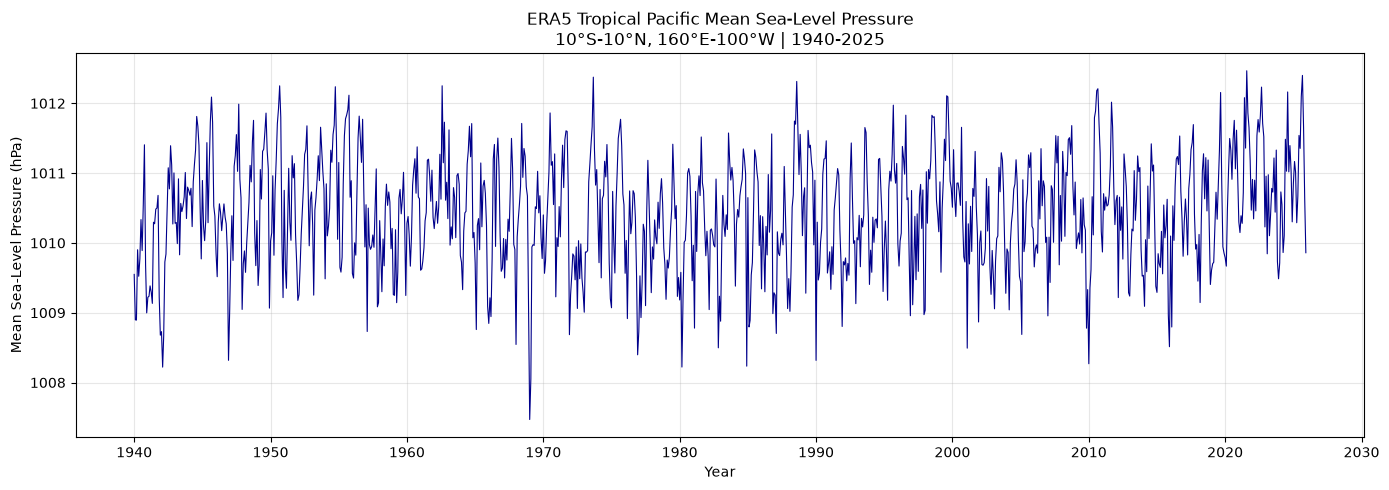


ERA5 PRESSURE VALIDATION RESULTS
[PASS] NetCDF file opens
[PASS] MSLP variable present
[PASS] Global spatial coverage
[PASS] Correct monthly time coverage
[PASS] Pressure values plausible
[PASS] No missing pressure values
[PASS] Global pressure map saved
[PASS] Pacific pressure time series saved
SUCCESS: ERA5 PRESSURE DATA PASSED ALL CHECKS!

Figures saved to: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_validation


In [12]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path

# ============================================================
# ERA5 MEAN SEA-LEVEL PRESSURE VALIDATION
# Global monthly data | 1940-2025
# ============================================================

DATA_FILE = Path(
    "data/era5/era5_global/"
    "era5_mean_sea_level_pressure_1940_2025.nc"
)

FIG_DIR = Path("figures/era5_validation")
FIG_DIR.mkdir(parents=True, exist_ok=True)

START_YEAR = 1940
END_YEAR = 2025

checks = {}

print("=" * 65)
print("ERA5 MEAN SEA-LEVEL PRESSURE VALIDATION")
print("=" * 65)

# ============================================================
# 1. FILE INTEGRITY
# ============================================================

print("\n[1/7] Checking file integrity...")

assert DATA_FILE.exists(), (
    f"File not found: {DATA_FILE.resolve()}"
)

size_gb = DATA_FILE.stat().st_size / 1024**3

print(f"File: {DATA_FILE.resolve()}")
print(f"File size: {size_gb:.2f} GB")

ds = xr.open_dataset(
    DATA_FILE,
    engine="netcdf4",
    chunks={"time": 12}
)

print("\nDataset:")
print(ds)

checks["NetCDF file opens"] = True

# ============================================================
# 2. CHECK VARIABLES AND DIMENSIONS
# ============================================================

print("\n[2/7] Checking variables and dimensions...")

# Handle different ERA5 time coordinate names
if "valid_time" in ds.dims:
    ds = ds.rename({"valid_time": "time"})

assert "msl" in ds.data_vars, (
    "Expected mean sea-level pressure variable 'msl'"
)

assert "time" in ds.dims
assert "latitude" in ds.dims
assert "longitude" in ds.dims

msl = ds["msl"]

print("Variable:", msl.name)
print("Dimensions:", dict(msl.sizes))
print("Units:", msl.attrs.get("units", "Unknown"))

checks["MSLP variable present"] = True

# ============================================================
# 3. VERIFY SPATIAL COVERAGE
# ============================================================

print("\n[3/7] Checking spatial coverage...")

nlat = ds.sizes["latitude"]
nlon = ds.sizes["longitude"]

lat_min = float(ds.latitude.min())
lat_max = float(ds.latitude.max())
lon_min = float(ds.longitude.min())
lon_max = float(ds.longitude.max())

print(f"Latitude points: {nlat}")
print(f"Longitude points: {nlon}")

print(f"Latitude range: {lat_min:.2f} to {lat_max:.2f}")
print(f"Longitude range: {lon_min:.2f} to {lon_max:.2f}")

checks["Global spatial coverage"] = (
    lat_min <= -89.75 and
    lat_max >= 89.75 and
    nlat >= 700 and
    nlon >= 1400
)

# ============================================================
# 4. VERIFY TEMPORAL COVERAGE
# ============================================================

print("\n[4/7] Checking temporal coverage...")

expected_months = (
    END_YEAR - START_YEAR + 1
) * 12

actual_months = ds.sizes["time"]

dates = pd.to_datetime(ds.time.values)

print("Expected months:", expected_months)
print("Actual months:", actual_months)

print("First date:", dates.min())
print("Last date:", dates.max())

# Compare year-month periods to avoid dependence
# on the exact day or hour used by ERA5.
actual_periods = pd.PeriodIndex(dates, freq="M")

expected_periods = pd.period_range(
    f"{START_YEAR}-01",
    f"{END_YEAR}-12",
    freq="M"
)

checks["Correct monthly time coverage"] = (
    actual_months == expected_months and
    actual_periods.equals(expected_periods)
)

# ============================================================
# 5. PRESSURE VALUES AND MISSING DATA
# ============================================================

print("\n[5/7] Checking pressure values...")

# ERA5 MSLP is normally stored in Pascals.
units = msl.attrs.get("units", "")

if units == "Pa":
    msl_hpa = msl / 100.0
elif units in ("hPa", "millibars", "mbar"):
    msl_hpa = msl
else:
    raise ValueError(
        f"Unexpected pressure units: {units}"
    )

msl_hpa.attrs["units"] = "hPa"

# Calculate statistics lazily using Dask.
# This may take some time for the full global archive.
stats = xr.Dataset({
    "minimum": msl_hpa.min(),
    "maximum": msl_hpa.max(),
    "mean": msl_hpa.mean(),
    "missing": msl_hpa.isnull().sum(),
    "total": xr.DataArray(msl_hpa.size)
}).compute()

p_min = float(stats["minimum"])
p_max = float(stats["maximum"])
p_mean = float(stats["mean"])
missing = int(stats["missing"])
total = int(stats["total"])

missing_pct = 100 * missing / total

print(f"Minimum pressure: {p_min:.2f} hPa")
print(f"Maximum pressure: {p_max:.2f} hPa")
print(f"Mean pressure:    {p_mean:.2f} hPa")
print(f"Missing values:   {missing:,}")
print(f"Missing percent:  {missing_pct:.6f}%")

# Broad sanity bounds, not strict physical limits.
checks["Pressure values plausible"] = (
    850 < p_min < 1050 and
    950 < p_mean < 1050 and
    950 < p_max < 1150
)

checks["No missing pressure values"] = (
    missing == 0
)

# ============================================================
# 6. GLOBAL PRESSURE MAP
# ============================================================

print("\n[6/7] Plotting global pressure map...")

# One month only: avoids loading entire archive.
sample = msl_hpa.sel(
    time="2020-01"
).squeeze().compute()

fig = plt.figure(figsize=(14, 7))

ax = plt.axes(
    projection=ccrs.Robinson()
)

sample.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
    vmin=980,
    vmax=1040,
    cbar_kwargs={
        "label": "Mean Sea-Level Pressure (hPa)"
    }
)

ax.coastlines(
    resolution="110m",
    linewidth=0.6
)

ax.set_global()

ax.set_title(
    "ERA5 Global Mean Sea-Level Pressure\n"
    "January 2020",
    fontsize=14
)

plt.tight_layout()

map_file = FIG_DIR / "mslp_global_jan2020.png"

plt.savefig(
    map_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

checks["Global pressure map saved"] = (
    map_file.exists()
)

# ============================================================
# 7. TROPICAL PACIFIC PRESSURE TIME SERIES
# ============================================================

print("\n[7/7] Plotting tropical Pacific pressure...")

# Convert longitude coordinates to 0-360.
msl_pacific = msl_hpa.assign_coords(
    longitude=msl_hpa.longitude % 360
).sortby("longitude").sortby("latitude")

# Tropical Pacific region
pacific = msl_pacific.sel(
    latitude=slice(-10, 10),
    longitude=slice(160, 260)
)

assert pacific.sizes["latitude"] > 0
assert pacific.sizes["longitude"] > 0

# Area-weighted average
weights = np.cos(
    np.deg2rad(pacific.latitude)
)

pacific_mean = pacific.weighted(weights).mean(
    dim=["latitude", "longitude"]
).compute()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    pacific_mean.time.values,
    pacific_mean.values,
    color="darkblue",
    linewidth=0.8
)

ax.set_title(
    "ERA5 Tropical Pacific Mean Sea-Level Pressure\n"
    "10°S-10°N, 160°E-100°W | 1940-2025"
)

ax.set_xlabel("Year")
ax.set_ylabel("Mean Sea-Level Pressure (hPa)")
ax.grid(alpha=0.3)

plt.tight_layout()

series_file = FIG_DIR / "mslp_pacific_timeseries.png"

plt.savefig(
    series_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

checks["Pacific pressure time series saved"] = (
    series_file.exists()
)

# ============================================================
# FINAL RESULTS
# ============================================================

print("\n" + "=" * 65)
print("ERA5 PRESSURE VALIDATION RESULTS")
print("=" * 65)

for name, passed in checks.items():
    status = "[PASS]" if passed else "[FAIL]"
    print(f"{status} {name}")

print("=" * 65)

if all(checks.values()):
    print("SUCCESS: ERA5 PRESSURE DATA PASSED ALL CHECKS!")
else:
    print("WARNING: Some validation checks failed.")

print(f"\nFigures saved to: {FIG_DIR.resolve()}")

ds.close()
